# 03 · Análise inferencial e testes de hipóteses

**Etapa III do roteiro.** Cada procedimento responde a uma pergunta de negócio da Etapa I.

Usamos apenas os procedimentos citados no roteiro: **Intervalo de Confiança, Teste t de Student, ANOVA, Qui-Quadrado e Teste de Correlação**.

### Roteiro aplicado em cada teste
1. Pergunta de negócio
2. Hipóteses **H₀** (nula) e **H₁** (alternativa)
3. Verificação dos **pressupostos**
4. **Escolha e justificativa** do teste
5. **Estatística, p-valor e decisão** com **α = 0,05**
6. **Tamanho de efeito**: se a diferença é grande o bastante para importar na prática
7. **Interpretação de negócio**

> **Regra de decisão:** se p-valor < 0,05, **rejeitamos H₀** (há evidência estatística do efeito). Se p-valor ≥ 0,05, **não rejeitamos H₀**. Isso não prova que H₀ é verdadeira, apenas que não há evidência suficiente contra ela.

> **Limitação geral:** este é um estudo **observacional**. Os testes indicam **associação**, não causalidade.

In [1]:
# ---------------------------------------------------------------
# Configuração do ambiente
# ---------------------------------------------------------------
# Localiza a raiz do projeto (pasta que contém "src/") para que os imports
# funcionem tanto rodando o notebook pelo Jupyter quanto pelo run_all.py.
import sys
from pathlib import Path

raiz = Path.cwd()
while not (raiz / "src").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config
from src import limpeza, descritiva, inferencia, graficos

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
graficos.aplicar_estilo()

In [2]:
df = limpeza.carregar_dados_limpos()
resultados = []        # todos os testes, para a tabela-resumo final
intervalos = []        # todos os ICs, para a tabela de ICs
print(f"n = {len(df)} · α = {config.ALFA} · confiança dos ICs = {config.CONFIANCA:.0%}")

n = 1470 · α = 0.05 · confiança dos ICs = 95%


---
## Q1 · Qual é a taxa de rotatividade e ela difere entre departamentos?

### Q1.a · Intervalo de confiança de 95% para a taxa de rotatividade
**Por que Wilson?** O IC "clássico" (p̂ ± 1,96·√(p̂(1−p̂)/n)) perde precisão quando a proporção está longe de 50% ou o grupo é pequeno (ex.: RH, n = 63). O método de **Wilson** mantém a cobertura de 95% nesses casos.

**Pressupostos:** amostra de observações independentes (cada linha é um funcionário único, verificado no notebook 01) e variável binária (saiu / ficou).

In [3]:
ic_geral = inferencia.ic_proporcao(int(df["Attrition_bin"].sum()), len(df))
intervalos.append({"pergunta": "Q1", "parametro": "Taxa de rotatividade geral", "estimativa": ic_geral["proporcao"] * 100,
                   "ic_inferior": ic_geral["ic_inferior"] * 100, "ic_superior": ic_geral["ic_superior"] * 100,
                   "unidade": "%", "metodo": "Wilson"})
display(Markdown(
    f"**Taxa de rotatividade = {ic_geral['proporcao']:.1%}** ({ic_geral['sucessos']} de {ic_geral['n']})  \n"
    f"**IC 95%: [{ic_geral['ic_inferior']:.1%}; {ic_geral['ic_superior']:.1%}]**".replace(".", ",")
))

t_dep = descritiva.taxa_saida_por_grupo(df, "Departamento")
for _, linha in t_dep.iterrows():
    intervalos.append({"pergunta": "Q1", "parametro": f"Taxa de rotatividade — {linha['Departamento']}",
                       "estimativa": linha["taxa_pct"], "ic_inferior": linha["ic_inf_pct"],
                       "ic_superior": linha["ic_sup_pct"], "unidade": "%", "metodo": "Wilson"})
t_dep.round(2)

**Taxa de rotatividade = 16,1%** (237 de 1470)  
**IC 95%: [14,3%; 18,1%]**

,Departamento,n,saidas,taxa_pct,ic_inf_pct,ic_sup_pct
0,P&D,961,133,13.84,11.80,16.17
1,Vendas,446,92,20.63,17.13,24.63
2,RH,63,12,19.05,11.25,30.41


**Interpretação:** com 95% de confiança, a taxa de rotatividade da população de funcionários fica **entre 14,3% e 18,1%**. Na prática, de cada 100 funcionários, **entre 14 e 18 deixam a empresa**. Esse número serve de **linha de base** para metas de retenção.

### Q1.b · Qui-Quadrado: a rotatividade depende do departamento?
- **H₀:** departamento e rotatividade são **independentes** (a taxa de saída é a mesma nos três departamentos).
- **H₁:** departamento e rotatividade estão **associados**.

**Teste escolhido:** Qui-Quadrado de independência, porque as duas variáveis são categóricas (departamento × saiu/ficou).
**Pressuposto:** todas as frequências esperadas devem ser ≥ 5.

In [4]:
q1 = inferencia.qui_quadrado(df, "Department", "Attrition",
                             "Q1 · A rotatividade difere entre departamentos?")
print("Tabela observada:"); display(q1["tabela_observada"])
print("Tabela esperada sob H0:"); display(q1["tabela_esperada"].round(1))
print(f"Pressuposto: menor frequência esperada = {q1['pressupostos']['menor_freq_esperada']:.1f} "
      f"→ {'OK (≥ 5)' if q1['pressupostos']['todas_esperadas_maior_igual_5'] else 'VIOLADO'}")
display(Markdown(inferencia.resumo_markdown(q1)))
resultados.append(q1)

Tabela observada:


Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,828,133
Sales,354,92


Tabela esperada sob H0:


Attrition,No,Yes
Department,,
Human Resources,52.80,10.20
Research & Development,806.10,154.90
Sales,374.10,71.90


Pressuposto: menor frequência esperada = 10.2 → OK (≥ 5)


**Qui-Quadrado de independência** — Department × Attrition

- H₀: Department e Attrition são independentes (a taxa de saída é a mesma em todos os níveis)
- H₁: Department e Attrition estão associadas
- Estatística: χ² = 10.796 · gl = 2
- p-valor = 0,0045
- **Decisão (α = 0,05): Rejeita H0**
- Tamanho de efeito: V de Cramér = 0.086 (desprezível)

**Decisão:** p-valor ≈ 0,0045 < 0,05, então **rejeitamos H₀**: a taxa de rotatividade **difere entre departamentos**.

**Interpretação de negócio:** Vendas (20,6%) perde proporcionalmente mais pessoas que P&D (13,8%). Porém o **V de Cramér = 0,086 é desprezível**: o departamento explica muito pouco da rotatividade. A diferença é real, mas pequena.

### Q1.c · Complemento: e por cargo?
Como os gráficos do notebook 02 sugeriram que o **cargo** pesa mais que o departamento, testamos também `JobRole × Attrition`.

In [5]:
q1c = inferencia.qui_quadrado(df, "JobRole", "Attrition", "Q1 · A rotatividade difere entre cargos?")
print(f"Menor frequência esperada = {q1c['pressupostos']['menor_freq_esperada']:.1f}")
display(Markdown(inferencia.resumo_markdown(q1c)))
resultados.append(q1c)

Menor frequência esperada = 8.4


**Qui-Quadrado de independência** — JobRole × Attrition

- H₀: JobRole e Attrition são independentes (a taxa de saída é a mesma em todos os níveis)
- H₁: JobRole e Attrition estão associadas
- Estatística: χ² = 86.190 · gl = 8
- p-valor = < 0,001
- **Decisão (α = 0,05): Rejeita H0**
- Tamanho de efeito: V de Cramér = 0.242 (pequeno)

**Decisão:** p-valor < 0,001, então **rejeitamos H₀**. **Interpretação:** o **efeito do cargo (V ≈ 0,24) é quase 3× maior que o do departamento (V ≈ 0,09)**, embora ainda classificado como pequeno. A ação de retenção deve ser **direcionada por cargo** (Representantes de Vendas, Técnicos de Laboratório e Analistas de RH), e não aplicada a um departamento inteiro.

---
## Q2 · Funcionários que saem ganham menos do que os que ficam?

- **H₀:** μ(renda | saiu) = μ(renda | ficou)
- **H₁:** μ(renda | saiu) ≠ μ(renda | ficou) (teste **bilateral**)

**Teste escolhido:** **Teste t para duas médias independentes**, porque comparamos uma variável quantitativa (renda) entre dois grupos.

### Verificação dos pressupostos
1. **Independência:** grupos formados por funcionários diferentes ✔
2. **Normalidade:** Shapiro-Wilk e gráfico Q-Q
3. **Homogeneidade das variâncias:** Levene. Se for rejeitada, usamos o **t de Welch**, que não exige variâncias iguais.

In [6]:
saiu = df.loc[df["Status"] == "Saiu", "MonthlyIncome"]
ficou = df.loc[df["Status"] == "Ficou", "MonthlyIncome"]
q2 = inferencia.teste_t(saiu, ficou, "Saiu", "Ficou", "MonthlyIncome",
                        "Q2 · Quem sai ganha menos do que quem fica?")

p = q2["pressupostos"]
for nome, r in zip(["Saiu", "Ficou"], p["normalidade_shapiro"]):
    print(f"Shapiro-Wilk ({nome}, n={r['n']}): W = {r['W']:.3f}, p = {inferencia.formatar_p(r['p_valor'])}, assimetria = {r['assimetria']:.2f}")
print(f"Levene: estatística = {p['levene']['estatistica']:.2f}, p = {inferencia.formatar_p(p['levene']['p_valor'])}"
      f" → variâncias {'iguais' if p['levene']['variancias_iguais'] else 'DIFERENTES → usar Welch'}")
print(f"TCL aplicável (n > 30 nos dois grupos): {p['tcl_aplicavel']}")

Shapiro-Wilk (Saiu, n=237): W = 0.780, p = < 0,001, assimetria = 1.91
Shapiro-Wilk (Ficou, n=1233): W = 0.834, p = < 0,001, assimetria = 1.28
Levene: estatística = 14.90, p = < 0,001 → variâncias DIFERENTES → usar Welch
TCL aplicável (n > 30 nos dois grupos): True


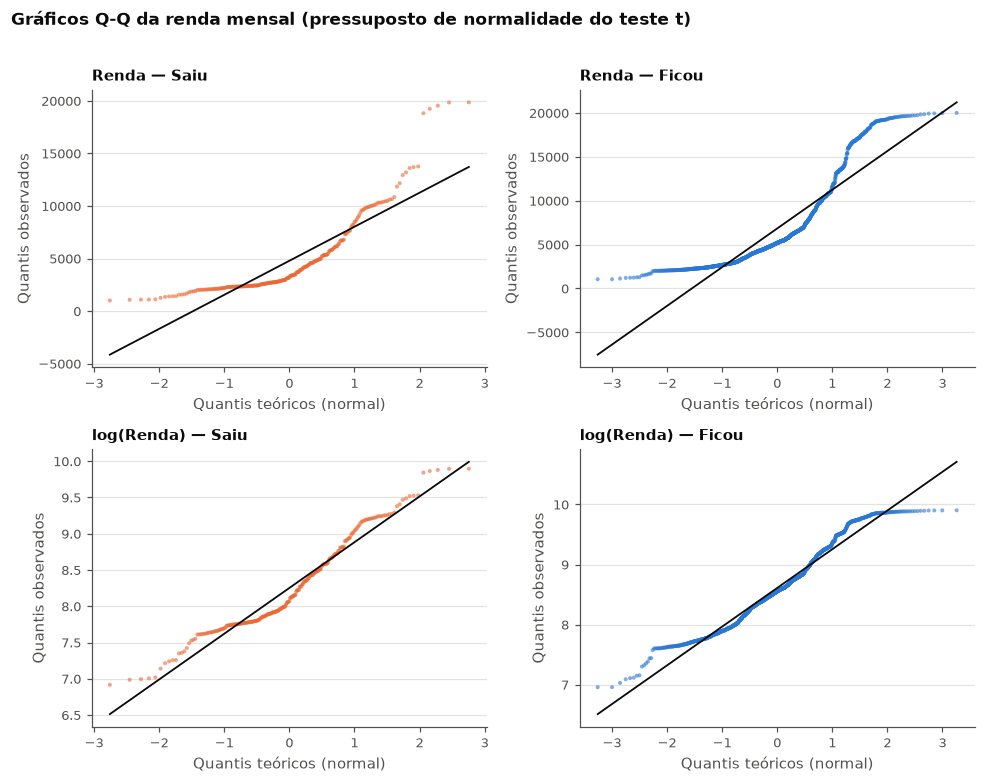

In [7]:
# Gráficos Q-Q: renda original e renda em escala logarítmica
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
graficos.qq_plot(axes[0, 0], saiu, "Renda — Saiu", config.COR_SAIU)
graficos.qq_plot(axes[0, 1], ficou, "Renda — Ficou", config.COR_FICOU)
graficos.qq_plot(axes[1, 0], np.log(saiu), "log(Renda) — Saiu", config.COR_SAIU)
graficos.qq_plot(axes[1, 1], np.log(ficou), "log(Renda) — Ficou", config.COR_FICOU)
fig.suptitle("Gráficos Q-Q da renda mensal (pressuposto de normalidade do teste t)", x=0.01, ha="left",
             fontsize=11, weight="bold", y=1.01)
fig.tight_layout()
graficos.salvar(fig, "fig12_pressupostos_qq")
plt.show()

**Leitura dos pressupostos:**
- O **Shapiro-Wilk rejeita a normalidade** nos dois grupos, e os gráficos Q-Q de cima mostram uma curva na cauda superior (renda assimétrica à direita).
- **Por que o teste t ainda é válido:** com **237 e 1.233 observações**, o **Teorema Central do Limite** garante que a distribuição da **média amostral** é aproximadamente normal, mesmo que os dados não sejam. É sobre a média que o teste t faz a inferência.
- O **Levene rejeita a igualdade de variâncias**, então usamos o **t de Welch**.
- **Verificação de robustez:** repetimos o teste t com o **logaritmo da renda**, que deixa a distribuição bem mais simétrica (gráficos Q-Q de baixo) e estabiliza as variâncias.

In [8]:
display(Markdown(inferencia.resumo_markdown(q2)))
resultados.append(q2)
intervalos.append({"pergunta": "Q2", "parametro": "Diferença de renda média (Saiu − Ficou)",
                   "estimativa": q2["diferenca_medias"], "ic_inferior": q2["ic_inferior"],
                   "ic_superior": q2["ic_superior"], "unidade": "US$", "metodo": "t de Welch"})

# Robustez: teste t na escala logarítmica
q2_log = inferencia.teste_t(np.log(saiu), np.log(ficou), "Saiu", "Ficou", "log(MonthlyIncome)",
                            "Q2 · Robustez: teste t com log(renda)")
display(Markdown("**Verificação de robustez (escala log):**\n\n" + inferencia.resumo_markdown(q2_log)))
razao = np.exp(q2_log["diferenca_medias"])
print(f"Na escala original: a renda 'típica' (média geométrica) de quem sai é {razao:.0%} da de quem fica "
      f"(IC 95%: {np.exp(q2_log['ic_inferior']):.0%} a {np.exp(q2_log['ic_superior']):.0%}).")
resultados.append(q2_log)

**t de Welch** — MonthlyIncome por grupo (Saiu × Ficou)

- H₀: μ(Saiu) = μ(Ficou): a média de MonthlyIncome é igual nos dois grupos
- H₁: μ(Saiu) ≠ μ(Ficou)
- Estatística: t = -7.483 · gl = 412.7
- p-valor = < 0,001
- **Decisão (α = 0,05): Rejeita H0**
- Tamanho de efeito: d de Cohen = -0.440 (pequeno)
- IC 95% da diferença de médias: [-2583.05; -1508.24]

**Verificação de robustez (escala log):**

**t de Student** — log(MonthlyIncome) por grupo (Saiu × Ficou)

- H₀: μ(Saiu) = μ(Ficou): a média de log(MonthlyIncome) é igual nos dois grupos
- H₁: μ(Saiu) ≠ μ(Ficou)
- Estatística: t = -7.748 · gl = 1468
- p-valor = < 0,001
- **Decisão (α = 0,05): Rejeita H0**
- Tamanho de efeito: d de Cohen = -0.550 (médio)
- IC 95% da diferença de médias: [-0.45; -0.27]

Na escala original: a renda 'típica' (média geométrica) de quem sai é 70% da de quem fica (IC 95%: 64% a 77%).


**Decisão:** p-valor < 0,001, então **rejeitamos H₀**. A renda média de quem sai é **estatisticamente menor**. O resultado se mantém na escala logarítmica, onde os pressupostos são atendidos (variâncias iguais pelo Levene).

**Interpretação de negócio:**
- Quem sai ganha em média **US$ 2.046 a menos por mês** (IC 95%: **US$ 1.508 a US$ 2.583** a menos).
- O efeito é **pequeno a médio** (d de Cohen ≈ −0,44).
- ⚠️ Como visto no notebook 02, **dentro do mesmo nível de cargo a renda de quem sai e de quem fica é quase igual**. A diferença vem de quem sai estar concentrado em **cargos de entrada**. A leitura correta é: **o risco está nos cargos de menor remuneração**, e não em "pessoas mal pagas em relação aos pares". Isso aponta para a **atratividade da carreira inicial** (salário de entrada e trilha de progressão), e não para reajustes individuais.

---
## Q3 · Envolvimento, ambiente, satisfação e equilíbrio vida-trabalho estão associados à saída?

Quatro testes **Qui-Quadrado de independência**, um para cada fator (escalas de 1 a 4 × saiu/ficou):

| Fator | H₀ | H₁ |
|---|---|---|
| Envolvimento com o trabalho | independente da saída | associado à saída |
| Satisfação com o ambiente | independente da saída | associado à saída |
| Satisfação com o trabalho | independente da saída | associado à saída |
| Equilíbrio vida-trabalho | independente da saída | associado à saída |

**Múltiplos testes:** fazer 4 testes ao mesmo tempo aumenta a chance de um "falso positivo". Por isso aplicamos a **correção de Holm**, que ajusta os p-valores para manter o erro global em 5%.

In [9]:
fatores_q3 = {
    "JobInvolvement": "Envolvimento com o trabalho",
    "EnvironmentSatisfaction": "Satisfação com o ambiente",
    "JobSatisfaction": "Satisfação com o trabalho",
    "WorkLifeBalance": "Equilíbrio vida-trabalho",
}
q3 = [inferencia.qui_quadrado(df, col, "Attrition", f"Q3 · {nome} × saída") for col, nome in fatores_q3.items()]
q3 = inferencia.ajustar_holm(q3)

for r, nome in zip(q3, fatores_q3.values()):
    display(Markdown(f"#### {nome}"))
    display(pd.concat([r["tabela_observada"],
                       (r["tabela_observada"]["Yes"] / r["tabela_observada"].sum(axis=1) * 100).rename("taxa_saida_%")], axis=1).round(1))
    print(f"Menor frequência esperada = {r['pressupostos']['menor_freq_esperada']:.1f} → "
          f"{'OK (≥ 5)' if r['pressupostos']['todas_esperadas_maior_igual_5'] else 'VIOLADO'}")
    display(Markdown(inferencia.resumo_markdown(r)))
resultados.extend(q3)

#### Envolvimento com o trabalho

,No,Yes,taxa_saida_%
JobInvolvement,,,
1,55,28,33.70
2,304,71,18.90
3,743,125,14.40
4,131,13,9.00


Menor frequência esperada = 13.4 → OK (≥ 5)


**Qui-Quadrado de independência** — JobInvolvement × Attrition

- H₀: JobInvolvement e Attrition são independentes (a taxa de saída é a mesma em todos os níveis)
- H₁: JobInvolvement e Attrition estão associadas
- Estatística: χ² = 28.492 · gl = 3
- p-valor = < 0,001 · p-valor ajustado (Holm) = < 0,001
- **Decisão (α = 0,05): Rejeita H0**
- Tamanho de efeito: V de Cramér = 0.139 (pequeno)

#### Satisfação com o ambiente

...

**Qui-Quadrado de independência** — JobSatisfaction × Attrition

- H₀: JobSatisfaction e Attrition são independentes (a taxa de saída é a mesma em todos os níveis)
- H₁: JobSatisfaction e Attrition estão associadas
- Estatística: χ² = 17.505 · gl = 3
- p-valor = < 0,001 · p-valor ajustado (Holm) = 0,0011
- **Decisão (α = 0,05): Rejeita H0**
- Tamanho de efeito: V de Cramér = 0.109 (pequeno)

#### Equilíbrio vida-trabalho

,No,Yes,taxa_saida_%
WorkLifeBalance,,,
1,55,25,31.20
2,286,58,16.90
3,766,127,14.20
4,126,27,17.60


Menor frequência esperada = 12.9 → OK (≥ 5)


**Qui-Quadrado de independência** — WorkLifeBalance × Attrition

- H₀: WorkLifeBalance e Attrition são independentes (a taxa de saída é a mesma em todos os níveis)
- H₁: WorkLifeBalance e Attrition estão associadas
- Estatística: χ² = 16.325 · gl = 3
- p-valor = < 0,001 · p-valor ajustado (Holm) = 0,0011
- **Decisão (α = 0,05): Rejeita H0**
- Tamanho de efeito: V de Cramér = 0.105 (pequeno)

**Decisão:** os **quatro testes rejeitam H₀**, mesmo após a correção de Holm (todos os p ajustados < 0,002). Todos os pressupostos foram atendidos (menor frequência esperada ≈ 12,9).

**Interpretação de negócio:**
- **Envolvimento com o trabalho é o fator de maior efeito** (V ≈ 0,14): quem tem envolvimento baixo sai **33,7%**, contra **9,0%** de quem tem envolvimento muito alto.
- **Satisfação com o ambiente** (V ≈ 0,12): o risco se concentra no nível **baixo** (25,4%).
- **Satisfação com o trabalho** e **equilíbrio vida-trabalho** (V ≈ 0,11) completam o quadro.
- Os efeitos individuais são **pequenos** (V entre 0,10 e 0,14), mas as quatro dimensões são **independentes entre si** (correlações ≈ 0 no notebook 02), então **seus efeitos se acumulam**. Um funcionário com várias dimensões no nível baixo acumula risco.
- ➜ Pesquisas de clima que identifiquem quem está no **nível "Baixo"** de qualquer dimensão são um **sistema de alerta precoce** de saída.

---
## Q4 · Fazer hora extra está associado a mais saídas?

- **H₀:** hora extra e rotatividade são **independentes**, ou seja, p(saída | hora extra) = p(saída | sem hora extra)
- **H₁:** hora extra e rotatividade estão **associadas**

**Teste escolhido:** **Qui-Quadrado 2×2** (com correção de continuidade de Yates, padrão para tabelas 2×2), complementado pelo **IC 95% da diferença de proporções** (método de Newcombe), que mostra o **tamanho** da diferença.

In [10]:
q4 = inferencia.qui_quadrado(df, "OverTime", "Attrition", "Q4 · Hora extra está associada à saída?")
display(q4["tabela_observada"])
print(f"Menor frequência esperada = {q4['pressupostos']['menor_freq_esperada']:.1f} → OK (≥ 5)")
display(Markdown(inferencia.resumo_markdown(q4)))
resultados.append(q4)

obs = q4["tabela_observada"]
ic_he = inferencia.ic_diferenca_proporcoes(int(obs.loc["Yes", "Yes"]), int(obs.loc["Yes"].sum()),
                                          int(obs.loc["No", "Yes"]), int(obs.loc["No"].sum()))
intervalos.append({"pergunta": "Q4", "parametro": "Diferença na taxa de saída (com − sem hora extra)",
                   "estimativa": ic_he["diferenca"] * 100, "ic_inferior": ic_he["ic_inferior"] * 100,
                   "ic_superior": ic_he["ic_superior"] * 100, "unidade": "p.p.", "metodo": "Newcombe"})
display(Markdown(
    f"- Taxa de saída **com** hora extra: **{ic_he['p1']:.1%}**  \n"
    f"- Taxa de saída **sem** hora extra: **{ic_he['p2']:.1%}**  \n"
    f"- **Diferença: {ic_he['diferenca']*100:.1f} p.p.** · IC 95%: [{ic_he['ic_inferior']*100:.1f}; {ic_he['ic_superior']*100:.1f}] p.p.  \n"
    f"- **Risco relativo: {ic_he['risco_relativo']:.2f}×**".replace(".", ",")
))

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


Menor frequência esperada = 67.1 → OK (≥ 5)


**Qui-Quadrado de independência (correção de Yates)** — OverTime × Attrition

- H₀: OverTime e Attrition são independentes (a taxa de saída é a mesma em todos os níveis)
- H₁: OverTime e Attrition estão associadas
- Estatística: χ² = 87.564 · gl = 1
- p-valor = < 0,001
- **Decisão (α = 0,05): Rejeita H0**
- Tamanho de efeito: V de Cramér = 0.244 (pequeno)

- Taxa de saída **com** hora extra: **30,5%**  
- Taxa de saída **sem** hora extra: **10,4%**  
- **Diferença: 20,1 p,p,** · IC 95%: [15,4; 25,0] p,p,  
- **Risco relativo: 2,93×**

**Decisão:** p-valor < 0,001 (χ² = 87,6), então **rejeitamos H₀**. O IC 95% da diferença (**15,4 a 25,0 p.p.**) **não contém zero**, o que confirma o resultado.

**Interpretação de negócio:**
- Quem faz hora extra tem **probabilidade de saída quase 3× maior** (risco relativo ≈ 2,9).
- É a **associação mais forte** de todo o estudo (V ≈ 0,24, o maior entre os fatores testados, junto com o cargo).
- Com 416 funcionários fazendo hora extra, se a taxa desse grupo caísse ao nível de quem não faz (10,4%), seriam **≈ 84 saídas a menos** (416 × 20,1 p.p.), cerca de **35% de todas as saídas**. Isso é um potencial, não uma garantia, já que a relação é de associação.

---
## Q5 · O desempenho e o envolvimento se refletem no reajuste salarial?

Três procedimentos, um para cada relação:

| Sub-pergunta | Teste | H₀ |
|---|---|---|
| Q5.a · Quem tem nota 4 recebe reajuste maior que quem tem nota 3? | **Teste t** (2 grupos) | μ(reajuste | nota 4) = μ(reajuste | nota 3) |
| Q5.b · O reajuste médio difere entre os 4 níveis de envolvimento? | **ANOVA** (4 grupos) | μ₁ = μ₂ = μ₃ = μ₄ |
| Q5.c · Quem ganha mais recebe reajuste maior (ou menor)? | **Teste de correlação** | ρ = 0 |

### Q5.a · Teste t: reajuste por avaliação de desempenho

In [11]:
nota4 = df.loc[df["PerformanceRating"] == 4, "PercentSalaryHike"]
nota3 = df.loc[df["PerformanceRating"] == 3, "PercentSalaryHike"]
q5a = inferencia.teste_t(nota4, nota3, "Nota 4", "Nota 3", "PercentSalaryHike",
                         "Q5 · Nota 4 recebe reajuste diferente da nota 3?")
p = q5a["pressupostos"]
print(f"n: nota 4 = {len(nota4)}, nota 3 = {len(nota3)} · TCL aplicável: {p['tcl_aplicavel']}")
print(f"Levene p = {inferencia.formatar_p(p['levene']['p_valor'])} → {'iguais' if p['levene']['variancias_iguais'] else 'diferentes → Welch'}")
print(f"Faixa de reajuste — nota 3: {nota3.min()}% a {nota3.max()}% · nota 4: {nota4.min()}% a {nota4.max()}%")
display(Markdown(inferencia.resumo_markdown(q5a)))
resultados.append(q5a)
intervalos.append({"pergunta": "Q5", "parametro": "Diferença de reajuste médio (nota 4 − nota 3)",
                   "estimativa": q5a["diferenca_medias"], "ic_inferior": q5a["ic_inferior"],
                   "ic_superior": q5a["ic_superior"], "unidade": "p.p.", "metodo": "t de Welch"})

n: nota 4 = 226, nota 3 = 1244 · TCL aplicável: True
Levene p = < 0,001 → diferentes → Welch
Faixa de reajuste — nota 3: 11% a 19% · nota 4: 20% a 25%


**t de Welch** — PercentSalaryHike por grupo (Nota 4 × Nota 3)

- H₀: μ(Nota 4) = μ(Nota 3): a média de PercentSalaryHike é igual nos dois grupos
- H₁: μ(Nota 4) ≠ μ(Nota 3)
- Estatística: t = 63.389 · gl = 457
- p-valor = < 0,001
- **Decisão (α = 0,05): Rejeita H0**
- Tamanho de efeito: d de Cohen = 3.382 (grande)
- IC 95% da diferença de médias: [7.60; 8.09]

**Decisão:** **rejeitamos H₀** (p < 0,001). **Interpretação:** nota 4 recebe em média **7,8 p.p. a mais** de reajuste (IC 95%: 7,6 a 8,1 p.p.). O d de Cohen ≈ 3,4 é enorme porque **as faixas não se sobrepõem**: a nota 3 recebe de 11% a 19%, e a nota 4 de 20% a 25%. Isso indica uma **regra fixa de reajuste atrelada à nota**. Os pressupostos (TCL e Welch) estão atendidos, mas o mais relevante para o negócio é que **o reajuste é uma consequência direta da avaliação**.

### Q5.b · ANOVA: reajuste por nível de envolvimento
- **H₀:** o reajuste médio é igual nos 4 níveis de envolvimento
- **H₁:** pelo menos um nível tem reajuste médio diferente

**Pressupostos:** normalidade dos resíduos (Shapiro + TCL, já que todos os grupos têm n > 30) e homogeneidade de variâncias (Levene). Se Levene rejeitar, usamos a ANOVA de Welch. Se H₀ for rejeitada, aplicamos o post-hoc de Tukey.

In [12]:
q5b = inferencia.anova(df, "PercentSalaryHike", "JobInvolvement",
                       "Q5 · O reajuste difere entre níveis de envolvimento?")
p = q5b["pressupostos"]
print(f"n por grupo: {p['n_por_grupo']} · TCL aplicável: {p['tcl_aplicavel']}")
print(f"Shapiro (resíduos): p = {inferencia.formatar_p(p['normalidade_residuos_shapiro']['p_valor'])}")
print(f"Levene: p = {p['levene']['p_valor']:.3f} → variâncias {'iguais → ANOVA clássica' if p['levene']['variancias_iguais'] else 'diferentes → Welch'}")
print("Médias de reajuste por nível:", {k: round(v, 2) for k, v in q5b["medias_por_grupo"].items()})
display(Markdown(inferencia.resumo_markdown(q5b)))
if q5b["tukey"] is not None:
    display(q5b["tukey"])
resultados.append(q5b)

n por grupo: {'1': 83, '2': 375, '3': 868, '4': 144} · TCL aplicável: True
Shapiro (resíduos): p = < 0,001
Levene: p = 0.725 → variâncias iguais → ANOVA clássica
Médias de reajuste por nível: {'1': np.float64(15.81), '2': np.float64(15.2), '3': np.float64(15.12), '4': np.float64(15.42)}


**ANOVA (F de Fisher)** — PercentSalaryHike por JobInvolvement (4 grupos)

- H₀: As médias de PercentSalaryHike são iguais em todos os níveis de JobInvolvement
- H₁: Pelo menos um nível de JobInvolvement tem média de PercentSalaryHike diferente
- Estatística: F = 1.077 · gl = (3; 1466.0)
- p-valor = 0,3579
- **Decisão (α = 0,05): Não rejeita H0**
- Tamanho de efeito: η² (eta quadrado) = 0.002 (desprezível)

**Decisão:** p-valor ≈ 0,36 > 0,05, então **não rejeitamos H₀** (o post-hoc não é necessário). O Levene não rejeitou a igualdade de variâncias, então a ANOVA clássica é adequada. A normalidade dos resíduos é rejeitada pelo Shapiro, mas com n ≥ 83 por grupo o TCL sustenta o teste.

**Interpretação de negócio:** **não há evidência de que o envolvimento seja recompensado no reajuste**: o reajuste médio fica entre 15,1% e 15,8% em todos os níveis (η² ≈ 0,002). Combinado com a Q3, temos uma **lacuna de reconhecimento**: o fator mais associado à permanência (envolvimento) não é considerado pela política salarial.

### Q5.c · Teste de correlação: renda × reajuste
- **H₀:** ρ = 0 (não há correlação entre renda mensal e reajuste)
- **H₁:** ρ ≠ 0

**Escolha do coeficiente:** a renda é fortemente assimétrica e tem outliers (notebook 01), e o diagrama de dispersão (Figura 9) não mostra uma relação linear. Por isso o principal é o **Spearman**, que é robusto a esses problemas. Pearson é reportado para comparação.

In [13]:
q5c = inferencia.teste_correlacao(df["MonthlyIncome"], df["PercentSalaryHike"], "MonthlyIncome",
                                  "PercentSalaryHike", "Q5 · Renda e reajuste são correlacionados?",
                                  metodo="spearman")
print(f"Pearson:  r = {q5c['pearson_r']:.3f}, p = {q5c['pearson_p']:.3f}, IC 95% = [{q5c['pearson_ic'][0]:.3f}; {q5c['pearson_ic'][1]:.3f}]")
print(f"Spearman: ρ = {q5c['spearman_rho']:.3f}, p = {q5c['spearman_p']:.3f}")
display(Markdown(inferencia.resumo_markdown(q5c)))
resultados.append(q5c)

Pearson:  r = -0.027, p = 0.296, IC 95% = [-0.078; 0.024]
Spearman: ρ = -0.034, p = 0.196


**Correlação de Spearman** — MonthlyIncome × PercentSalaryHike

- H₀: ρ = 0: não há correlação entre MonthlyIncome e PercentSalaryHike
- H₁: ρ ≠ 0: há correlação
- Estatística: ρ = -0.034 · gl = 1468
- p-valor = 0,1957
- **Decisão (α = 0,05): Não rejeita H0**
- Tamanho de efeito: r² (variância compartilhada) = 0.001 (desprezível)

**Decisão:** p-valor ≈ 0,20 > 0,05, então **não rejeitamos H₀**. O IC 95% de Pearson (−0,08 a 0,02) contém zero.

**Interpretação de negócio:** o percentual de reajuste **não depende do nível salarial**: a política trata todas as faixas de renda da mesma forma. Somado à Q5.a e à Q5.b: **o reajuste é definido só pela nota de desempenho**. E a nota **não está associada à saída** (16,1% × 16,4%, notebook 02). Ou seja, a principal ferramenta de recompensa da empresa **não atua sobre os fatores que explicam a rotatividade**.

---
## Resumo da inferência

In [14]:
tab_ic = pd.DataFrame(intervalos)
descritiva.salvar_tabela(tab_ic.round(3), "intervalos_confianca", index=False)
tab_ic.round(2)

,pergunta,parametro,estimativa,ic_inferior,ic_superior,unidade,metodo
0,Q1,Taxa de rotatividade geral,16.12,14.33,18.09,%,Wilson
1,Q1,Taxa de rotatividade — P&D,13.84,11.80,16.17,%,Wilson
2,Q1,Taxa de rotatividade — Vendas,20.63,17.13,24.63,%,Wilson
3,Q1,Taxa de rotatividade — RH,19.05,11.25,30.41,%,Wilson
4,Q2,Diferença de renda média (Saiu − Ficou),"-2,045.65","-2,583.05","-1,508.24",US$,t de Welch
5,Q4,Diferença na taxa de saída (com − sem hora extra),20.09,15.42,24.99,p.p.,Newcombe
6,Q5,Diferença de reajuste médio (nota 4 − nota 3),7.85,7.60,8.09,p.p.,t de Welch


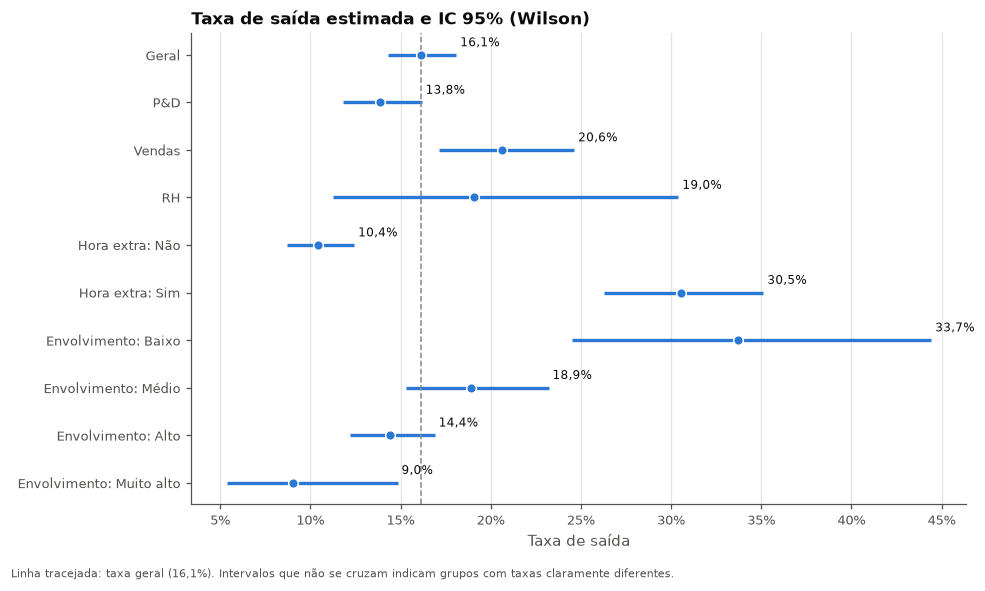

In [15]:
# Gráfico dos intervalos de confiança principais
taxas = tab_ic[tab_ic["unidade"] == "%"].copy()
taxas["rotulo"] = taxas["parametro"].str.replace("Taxa de rotatividade — ", "").str.replace("Taxa de rotatividade geral", "Geral")
t_he = descritiva.taxa_saida_por_grupo(df, "HoraExtra").rename(columns={"HoraExtra": "rotulo", "taxa_pct": "estimativa",
                                                                      "ic_inf_pct": "ic_inferior", "ic_sup_pct": "ic_superior"})
t_he["rotulo"] = "Hora extra: " + t_he["rotulo"].astype(str)
t_env = descritiva.taxa_saida_por_grupo(df, "JobInvolvement_rot").rename(columns={"JobInvolvement_rot": "rotulo", "taxa_pct": "estimativa",
                                                                                 "ic_inf_pct": "ic_inferior", "ic_sup_pct": "ic_superior"})
t_env["rotulo"] = "Envolvimento: " + t_env["rotulo"].astype(str)
painel = pd.concat([taxas[["rotulo", "estimativa", "ic_inferior", "ic_superior"]],
                    t_he[["rotulo", "estimativa", "ic_inferior", "ic_superior"]],
                    t_env[["rotulo", "estimativa", "ic_inferior", "ic_superior"]]], ignore_index=True)

fig, ax = plt.subplots(figsize=(9, 5.2))
graficos.grafico_ics(ax, painel, "rotulo", "estimativa", "ic_inferior", "ic_superior",
                     referencia=ic_geral["proporcao"] * 100,
                     titulo="Taxa de saída estimada e IC 95% (Wilson)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(decimals=0))
ax.set_xlabel("Taxa de saída")
fig.text(0.01, -0.02, "Linha tracejada: taxa geral (16,1%). Intervalos que não se cruzam indicam grupos com taxas claramente diferentes.",
         fontsize=7.5, color=config.COR_TEXTO_SEC)
fig.tight_layout()
graficos.salvar(fig, "fig13_intervalos_confianca")
plt.show()

In [16]:
resumo = inferencia.tabela_resumo(resultados)
descritiva.salvar_tabela(resumo, "resultados_inferencia", index=False)
resumo.assign(p_valor=resumo["p_valor"].map(inferencia.formatar_p),
              p_valor_holm=resumo["p_valor_holm"].map(lambda v: "—" if pd.isna(v) else inferencia.formatar_p(v))
             ).drop(columns=["H0"])

,pergunta,teste,variaveis,estatistica,gl,p_valor,p_valor_holm,decisao,efeito
0,Q1 · A rotatividade difere entre departamentos?,Qui-Quadrado de independência,Department × Attrition,χ² = 10.796,2,"0,0045",—,Rejeita H0,V de Cramér = 0.086 (desprezível)
1,Q1 · A rotatividade difere entre cargos?,Qui-Quadrado de independência,JobRole × Attrition,χ² = 86.190,8,"< 0,001",—,Rejeita H0,V de Cramér = 0.242 (pequeno)
2,Q2 · Quem sai ganha menos do que quem fica?,t de Welch,MonthlyIncome por grupo (Saiu × Ficou),t = -7.483,412.7,"< 0,001",—,Rejeita H0,d de Cohen = -0.440 (pequeno)
3,Q2 · Robustez: teste t com log(renda),t de Student,log(MonthlyIncome) por grupo (Saiu × Ficou),t = -7.748,1468,"< 0,001",—,Rejeita H0,d de Cohen = -0.550 (médio)
4,Q3 · Envolvimento com o trabalho × saída,Qui-Quadrado de independência,JobInvolvement × Attrition,χ² = 28.492,3,"< 0,001","< 0,001",Rejeita H0,V de Cramér = 0.139 (pequeno)
5,Q3 · Satisfação com o ambiente × saída,Qui-Quadrado de independência,EnvironmentSatisfaction × Attrition,χ² = 22.504,3,"< 0,001","< 0,001",Rejeita H0,V de Cramér = 0.124 (pequeno)
6,Q3 · Satisfação com o trabalho × saída,Qui-Quadrado de independência,JobSatisfaction × Attrition,χ² = 17.505,3,"< 0,001","0,0011",Rejeita H0,V de Cramér = 0.109 (pequeno)
7,Q3 · Equilíbrio vida-trabalho × saída,Qui-Quadrado de independência,WorkLifeBalance × Attrition,χ² = 16.325,3,"< 0,001","0,0011",Rejeita H0,V de Cramér = 0.105 (pequeno)
8,Q4 · Hora extra está associada à saída?,Qui-Quadrado de independência (correção de Yates),OverTime × Attrition,χ² = 87.564,1,"< 0,001",—,Rejeita H0,V de Cramér = 0.244 (pequeno)
9,Q5 · Nota 4 recebe reajuste diferente da nota 3?,t de Welch,PercentSalaryHike por grupo (Nota 4 × Nota 3),t = 63.389,457.0,"< 0,001",—,Rejeita H0,d de Cohen = 3.382 (grande)


In [17]:
# Números-chave salvos em JSON: o relatório lê daqui, para que nenhum número seja digitado à mão
import json
t_faixa = descritiva.taxa_saida_por_grupo(df, "FaixaSalarial")
t_cargo = descritiva.taxa_saida_por_grupo(df, "Cargo").set_index("Cargo")
t_inv = descritiva.taxa_saida_por_grupo(df, "JobInvolvement_rot").set_index("JobInvolvement_rot")
t_amb = descritiva.taxa_saida_por_grupo(df, "EnvironmentSatisfaction_rot").set_index("EnvironmentSatisfaction_rot")
t_wlb = descritiva.taxa_saida_por_grupo(df, "WorkLifeBalance_rot").set_index("WorkLifeBalance_rot")
t_he2 = descritiva.taxa_saida_por_grupo(df, "HoraExtra").set_index("HoraExtra")
numeros = {
    "n": len(df), "saidas": int(df["Attrition_bin"].sum()),
    "taxa_geral": ic_geral["proporcao"] * 100, "taxa_ic": [ic_geral["ic_inferior"] * 100, ic_geral["ic_superior"] * 100],
    "taxa_he_sim": t_he2.loc["Sim", "taxa_pct"], "taxa_he_nao": t_he2.loc["Não", "taxa_pct"],
    "n_he_sim": int(t_he2.loc["Sim", "n"]),
    "he_diff": ic_he["diferenca"] * 100, "he_diff_ic": [ic_he["ic_inferior"] * 100, ic_he["ic_superior"] * 100],
    "he_rr": ic_he["risco_relativo"], "he_chi2": q4["estatistica"], "he_v": q4["efeito"],
    "renda_media_saiu": q2["media_a"], "renda_media_ficou": q2["media_b"],
    "renda_mediana_saiu": float(saiu.median()), "renda_mediana_ficou": float(ficou.median()),
    "renda_diff": q2["diferenca_medias"], "renda_diff_ic": [q2["ic_inferior"], q2["ic_superior"]],
    "renda_t": q2["estatistica"], "renda_gl": float(q2["gl"]), "renda_d": q2["efeito"],
    "taxa_q1_renda": float(t_faixa.iloc[0]["taxa_pct"]), "taxa_q4_renda": float(t_faixa.iloc[-1]["taxa_pct"]),
    "taxa_rep_vendas": t_cargo.loc["Representante de Vendas", "taxa_pct"],
    "taxa_tec_lab": t_cargo.loc["Técnico de Laboratório", "taxa_pct"],
    "dep_chi2": q1["estatistica"], "dep_p": q1["p_valor"], "dep_v": q1["efeito"],
    "cargo_chi2": q1c["estatistica"], "cargo_v": q1c["efeito"],
    "inv_baixo": t_inv.loc["Baixo", "taxa_pct"], "inv_muito_alto": t_inv.loc["Muito alto", "taxa_pct"],
    "amb_baixo": t_amb.loc["Baixo", "taxa_pct"], "wlb_ruim": t_wlb.loc["Ruim", "taxa_pct"],
    "q3_v": {r["variaveis"]: r["efeito"] for r in q3},
    "q3_p_holm": {r["variaveis"]: r["p_valor_holm"] for r in q3},
    "q3_chi2": {r["variaveis"]: r["estatistica"] for r in q3},
    "reajuste_nota4": q5a["media_a"], "reajuste_nota3": q5a["media_b"],
    "reajuste_diff_ic": [q5a["ic_inferior"], q5a["ic_superior"]], "reajuste_t": q5a["estatistica"],
    "anova_f": q5b["estatistica"], "anova_p": q5b["p_valor"], "anova_eta2": q5b["efeito"],
    "corr_rho": q5c["spearman_rho"], "corr_p": q5c["spearman_p"],
    "taxa_nota3": float(df.loc[df["PerformanceRating"] == 3, "Attrition_bin"].mean() * 100),
    "taxa_nota4": float(df.loc[df["PerformanceRating"] == 4, "Attrition_bin"].mean() * 100),
}
numeros = {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in numeros.items()}
with open(config.PASTA_TABELAS / "numeros_chave.json", "w", encoding="utf-8") as f:
    json.dump(numeros, f, ensure_ascii=False, indent=2, default=float)
print("Números-chave salvos em reports/tables/numeros_chave.json")

Números-chave salvos em reports/tables/numeros_chave.json


## Conclusões da Etapa III

| Pergunta | Resultado | Decisão (α = 0,05) | Efeito |
|---|---|---|---|
| **Q1** Taxa e departamento | Taxa = 16,1% (IC 95%: 14,3%–18,1%); Vendas > P&D | Rejeita H₀ | Desprezível (departamento) · pequeno, ≈ 3× maior (cargo) |
| **Q2** Salário | Quem sai ganha US$ 2.046 a menos em média (IC: 1.508–2.583) | Rejeita H₀ | Pequeno a médio; reflete senioridade |
| **Q3** Envolvimento e ambiente | Os 4 fatores associados à saída (Holm) | Rejeita H₀ (×4) | Pequeno, mas cumulativo |
| **Q4** Hora extra | 30,5% × 10,4%; RR ≈ 2,9 (IC da diferença: 15,4–25,0 p.p.) | Rejeita H₀ | **Maior efeito do estudo** |
| **Q5** Desempenho e reajuste | Reajuste depende só da nota (t); não do envolvimento (ANOVA) nem da renda (correlação) | Rejeita / Não rejeita / Não rejeita | Lacuna de reconhecimento |

**Mensagem central:** a rotatividade está mais associada a **hora extra**, **início de carreira** (cargos de entrada e menor renda) e **baixo envolvimento**. A política de reajuste, por sua vez, considera só a nota de desempenho, que **não diferencia quem sai de quem fica**.